In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dataset_B_training.csv to dataset_B_training.csv
Saving dataset_B_testing.csv to dataset_B_testing.csv
Saving Dataset B Information.pdf to Dataset B Information.pdf
Saving dataset_B_example_submission.csv to dataset_B_example_submission.csv


|| I worked on Data Visualisation and Exploratory Data Analysis ||

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
train = pd.read_csv("dataset_B_training.csv")
test = pd.read_csv("dataset_B_testing.csv")
sample = pd.read_csv("dataset_B_example_submission.csv")

print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)
print("Submission dataset:", sample.shape)

Training dataset: (4756, 31)
Testing dataset: (4749, 30)
Submission dataset: (4749, 2)


In [ ]:
print(train.head())
print(train.info())
print(train.describe(include="all"))

   respondent_id  h1n1_concern  h1n1_knowledge  behavioral_antiviral_meds  \
0              1           1.0             2.0                        0.0   
1              2           1.0             1.0                        0.0   
2              3           2.0             1.0                        0.0   
3              4           0.0             1.0                        0.0   
4              5           2.0             0.0                        0.0   

   behavioral_avoidance  behavioral_face_mask  behavioral_wash_hands  \
0                   1.0                   0.0                    1.0   
1                   0.0                   0.0                    0.0   
2                   1.0                   0.0                    1.0   
3                   1.0                   0.0                    1.0   
4                   0.0                   0.0                    0.0   

   behavioral_large_gatherings  behavioral_outside_home  \
0                          0.0               

In [ ]:
print(train["h1n1_vaccine"].value_counts())

print(train["h1n1_vaccine"].value_counts(normalize=True) * 100)

h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64
h1n1_vaccine
0    60.59714
1    39.40286
Name: proportion, dtype: float64


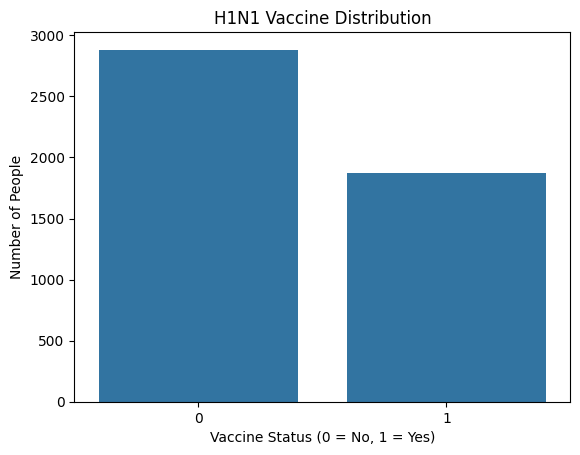

In [ ]:
sns.countplot(data=train, x="h1n1_vaccine")

plt.title("H1N1 Vaccine Distribution")
plt.xlabel("Vaccine Status (0 = No, 1 = Yes)")
plt.ylabel("Number of People")

plt.show()

In [ ]:
missing = train.isnull().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

print(missing)

employment_sector              2364
health_insurance               1925
income_poverty                  712
doctor_recc_h1n1                319
rent_or_own                     315
employment_status               235
marital_status                  226
education                       224
child_under_6_months            134
health_worker                   131
opinion_h1n1_vacc_effective      69
opinion_h1n1_risk                64
opinion_h1n1_sick_from_vacc      64
household_adults                 34
household_children               34
behavioral_avoidance             27
h1n1_knowledge                   22
behavioral_touch_face            20
behavioral_antiviral_meds        17
h1n1_concern                     15
behavioral_outside_home          15
behavioral_large_gatherings       9
behavioral_wash_hands             8
behavioral_face_mask              4
dtype: int64


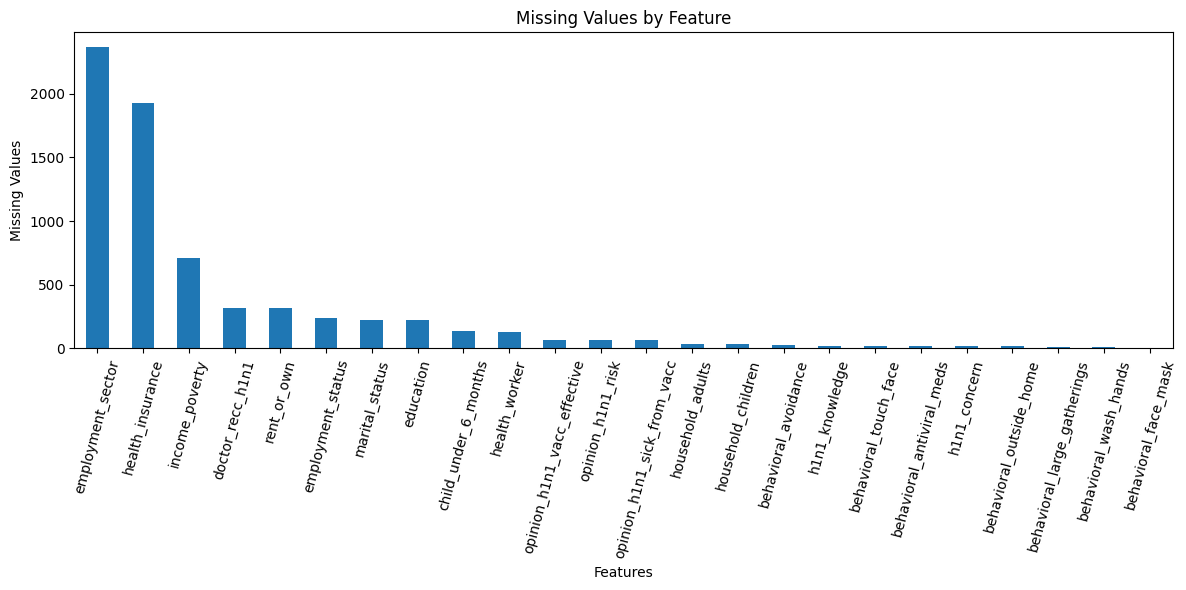

In [ ]:
plt.figure(figsize=(12, 6))

missing.plot(kind="bar")

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Values")

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

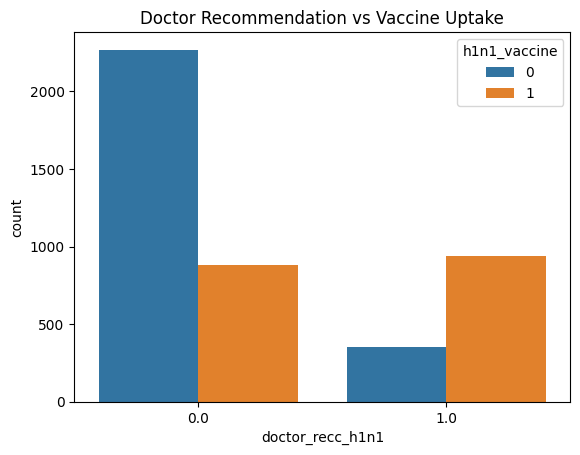

In [ ]:
sns.countplot(
    data=train,
    x="doctor_recc_h1n1",
    hue="h1n1_vaccine"
)

plt.title("Doctor Recommendation vs Vaccine Uptake")
plt.show()

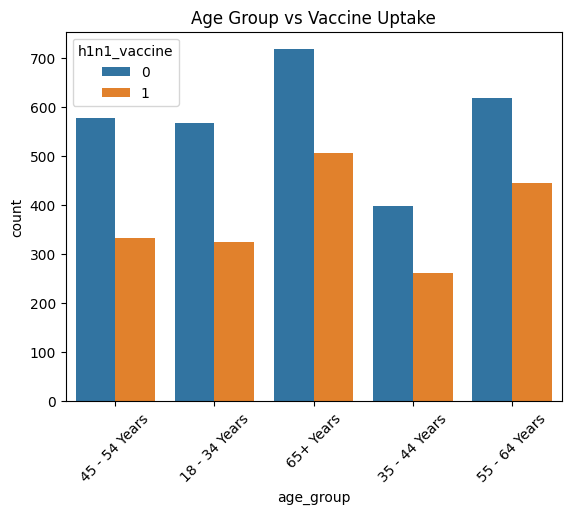

In [ ]:
sns.countplot(
    data=train,
    x="age_group",
    hue="h1n1_vaccine"
)

plt.title("Age Group vs Vaccine Uptake")
plt.xticks(rotation=45)
plt.show()

In [ ]:
X = train.drop(
    columns=["respondent_id", "h1n1_vaccine"]
)

y = train["h1n1_vaccine"]

X_test = test.drop(columns=["respondent_id"])

In [ ]:
numeric_cols = X.select_dtypes(
    include=["number"]
).columns

categorical_cols = X.select_dtypes(
    exclude=["number"]
).columns

print("Numerical:", list(numeric_cols))
print("Categorical:", list(categorical_cols))

Numerical: ['h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'household_adults', 'household_children', 'number_chronic_med_conditions']
Categorical: ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape)
print("Validation records:", X_val.shape)

print("Training target:", y_train.shape)
print("Validation target:", y_val.shape)

Training records: (3804, 29)
Validation records: (952, 29)
Training target: (3804,)
Validation target: (952,)


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [ ]:
log_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

log_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [ ]:
y_pred = log_model.predict(X_val)

y_prob = log_model.predict_proba(X_val)[:, 1]

print("Predictions completed!")

Predictions completed!


In [ ]:
print("Accuracy:", accuracy_score(y_val, y_pred))

print("Precision:", precision_score(y_val, y_pred))

print("Recall:", recall_score(y_val, y_pred))

print("F1 Score:", f1_score(y_val, y_pred))

print("ROC-AUC:", roc_auc_score(y_val, y_prob))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

Accuracy: 0.7605042016806722
Precision: 0.7289719626168224
Recall: 0.624
F1 Score: 0.6724137931034483
ROC-AUC: 0.8165545927209705

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.85      0.81       577
           1       0.73      0.62      0.67       375

    accuracy                           0.76       952
   macro avg       0.75      0.74      0.74       952
weighted avg       0.76      0.76      0.76       952



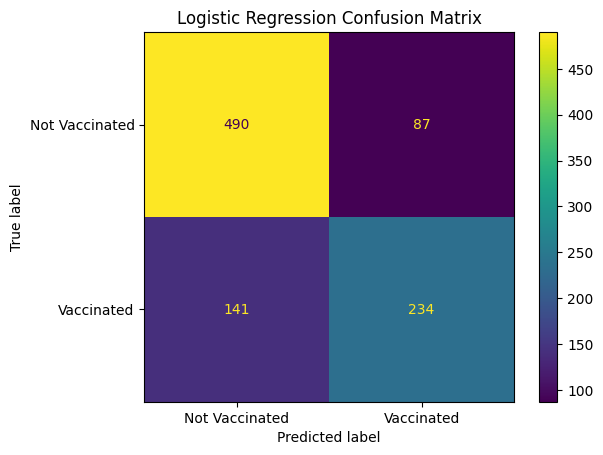

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    display_labels=["Not Vaccinated", "Vaccinated"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [ ]:
rf_pred = rf_model.predict(X_val)

rf_prob = rf_model.predict_proba(X_val)[:, 1]

print("Predictions completed!")

Predictions completed!


In [ ]:
print("Accuracy:", accuracy_score(y_val, rf_pred))

print("Precision:", precision_score(y_val, rf_pred))

print("Recall:", recall_score(y_val, rf_pred))

print("F1 Score:", f1_score(y_val, rf_pred))

print("ROC-AUC:", roc_auc_score(y_val, rf_prob))

Accuracy: 0.7542016806722689
Precision: 0.719626168224299
Recall: 0.616
F1 Score: 0.6637931034482759
ROC-AUC: 0.7964852686308493


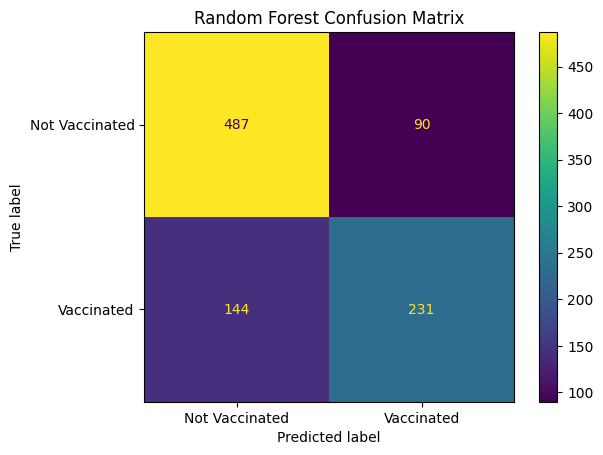

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    rf_pred,
    display_labels=["Not Vaccinated", "Vaccinated"]
)

plt.title("Random Forest Confusion Matrix")
plt.show()

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.base import clone

In [ ]:
gb_preprocessor = clone(preprocessor)
gb_preprocessor.set_params(sparse_threshold=0)

print("Gradient Boosting preprocessing ready!")

Gradient Boosting preprocessing ready!


In [ ]:
gb_model = Pipeline([
    ("preprocessing", gb_preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

In [ ]:
gb_model.fit(X_train, y_train)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


In [ ]:
gb_pred = gb_model.predict(X_val)

gb_prob = gb_model.predict_proba(X_val)[:, 1]

print("Predictions completed!")

Predictions completed!


In [ ]:
print("Accuracy:", accuracy_score(y_val, gb_pred))

print("Precision:", precision_score(y_val, gb_pred))

print("Recall:", recall_score(y_val, gb_pred))

print("F1 Score:", f1_score(y_val, gb_pred))

print("ROC-AUC:", roc_auc_score(y_val, gb_prob))

Accuracy: 0.7636554621848739
Precision: 0.734375
Recall: 0.6266666666666667
F1 Score: 0.6762589928057554
ROC-AUC: 0.8085615251299826


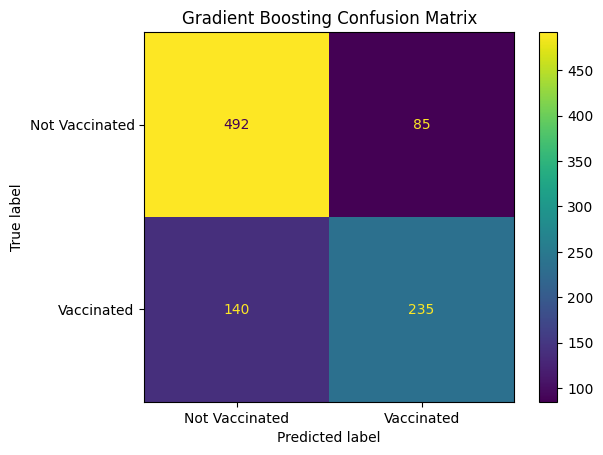

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    gb_pred,
    display_labels=["Not Vaccinated", "Vaccinated"]
)

plt.title("Gradient Boosting Confusion Matrix")
plt.show()

In [ ]:
!pip -q install xgboost

In [ ]:
from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [ ]:
xgb_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

In [ ]:
xgb_model.fit(X_train, y_train)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [ ]:
xgb_pred = xgb_model.predict(X_val)

xgb_prob = xgb_model.predict_proba(X_val)[:, 1]

print("XGBoost predictions completed!")

XGBoost predictions completed!


In [ ]:
print("Accuracy:", accuracy_score(y_val, xgb_pred))

print("Precision:", precision_score(y_val, xgb_pred))

print("Recall:", recall_score(y_val, xgb_pred))

print("F1 Score:", f1_score(y_val, xgb_pred))

print("ROC-AUC:", roc_auc_score(y_val, xgb_prob))

Accuracy: 0.7626050420168067
Precision: 0.7264437689969605
Recall: 0.6373333333333333
F1 Score: 0.6789772727272727
ROC-AUC: 0.8135597920277297


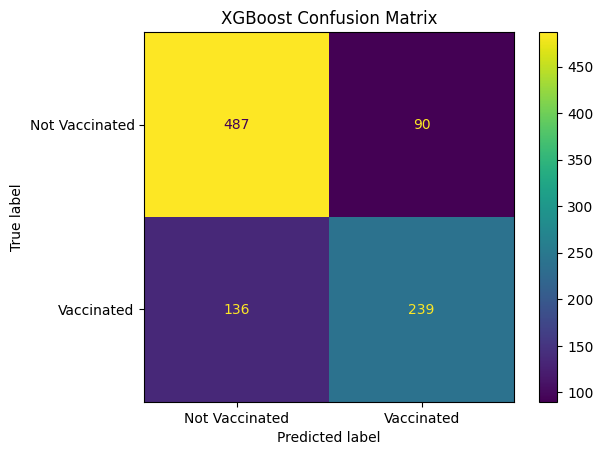

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    xgb_pred,
    display_labels=["Not Vaccinated", "Vaccinated"]
)

plt.title("XGBoost Confusion Matrix")
plt.show()

In [ ]:
models = {
    "Logistic Regression": log_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1 Score": f1_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

comparison = pd.DataFrame(results)

print(comparison.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.7605     0.7290  0.6240    0.6724   0.8166
      Random Forest    0.7542     0.7196  0.6160    0.6638   0.7965
  Gradient Boosting    0.7637     0.7344  0.6267    0.6763   0.8086
            XGBoost    0.7626     0.7264  0.6373    0.6790   0.8136


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    print(name)
    print("Mean ROC-AUC:", scores.mean().round(4))
    print("Standard Deviation:", scores.std().round(4))
    print("--------------------------")

Logistic Regression
Mean ROC-AUC: 0.8229
Standard Deviation: 0.0128
--------------------------
Random Forest
Mean ROC-AUC: 0.8165
Standard Deviation: 0.0137
--------------------------
Gradient Boosting
Mean ROC-AUC: 0.824
Standard Deviation: 0.013
--------------------------
XGBoost
Mean ROC-AUC: 0.8271
Standard Deviation: 0.013
--------------------------


In [ ]:

import pandas as pd

url = "https://data.cdc.gov/resource/kvib-3txy.csv?$limit=50000"

hospital_df = pd.read_csv(url)

print("Dataset shape:", hospital_df.shape)
print("\nColumn names:")
print(hospital_df.columns.tolist())

print("\nFirst 5 rows:")
display(hospital_df.head())


Dataset shape: (50000, 12)

Column names:
['surveillance_network', 'season', 'date_type', 'date', 'age_category', 'race', 'sex', 'state', 'data_type', 'estimate_type', 'rate_type', 'estimate']

First 5 rows:


,surveillance_network,season,date_type,date,age_category,race,sex,state,data_type,estimate_type,rate_type,estimate
0,COVID-NET,2019-20,Week Ending Date,2020-03-07,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,0.0
1,COVID-NET,2019-20,Week Ending Date,2020-03-14,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,0.0
2,COVID-NET,2019-20,Week Ending Date,2020-03-21,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,2.0
3,COVID-NET,2019-20,Week Ending Date,2020-03-28,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,7.0
4,COVID-NET,2019-20,Week Ending Date,2020-04-04,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,11.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

# Check dataset size
print("Rows and columns:", hospital_df.shape)

# Check all column names
print("\nColumn names:")
print(hospital_df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(hospital_df.isnull().sum())

# Display first 10 records
display(hospital_df.head(10))


Rows and columns: (50000, 12)

Column names:
['surveillance_network', 'season', 'date_type', 'date', 'age_category', 'race', 'sex', 'state', 'data_type', 'estimate_type', 'rate_type', 'estimate']

Missing values:
surveillance_network    0
season                  0
date_type               0
date                    0
age_category            0
race                    0
sex                     0
state                   0
data_type               0
estimate_type           0
rate_type               0
estimate                0
dtype: int64


,surveillance_network,season,date_type,date,age_category,race,sex,state,data_type,estimate_type,rate_type,estimate
0,COVID-NET,2019-20,Week Ending Date,2020-03-07,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,0.0
1,COVID-NET,2019-20,Week Ending Date,2020-03-14,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,0.0
2,COVID-NET,2019-20,Week Ending Date,2020-03-21,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,2.0
3,COVID-NET,2019-20,Week Ending Date,2020-03-28,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,7.0
4,COVID-NET,2019-20,Week Ending Date,2020-04-04,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,11.0
5,COVID-NET,2019-20,Week Ending Date,2020-04-11,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,16.0
6,COVID-NET,2019-20,Week Ending Date,2020-04-18,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,21.0
7,COVID-NET,2019-20,Week Ending Date,2020-04-25,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,26.0
8,COVID-NET,2019-20,Week Ending Date,2020-05-02,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,31.0
9,COVID-NET,2019-20,Week Ending Date,2020-05-09,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,37.0


In [ ]:

print("COLUMN NAMES:")
print(hospital_df.columns.tolist())

print("\nFIRST 10 RECORDS:")
display(hospital_df.head(10))

print("\nDATA TYPES:")
print(hospital_df.dtypes)

print("\nMISSING VALUES:")
print(hospital_df.isnull().sum())


COLUMN NAMES:
['surveillance_network', 'season', 'date_type', 'date', 'age_category', 'race', 'sex', 'state', 'data_type', 'estimate_type', 'rate_type', 'estimate']

FIRST 10 RECORDS:


,surveillance_network,season,date_type,date,age_category,race,sex,state,data_type,estimate_type,rate_type,estimate
0,COVID-NET,2019-20,Week Ending Date,2020-03-07,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,0.0
1,COVID-NET,2019-20,Week Ending Date,2020-03-14,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,0.0
2,COVID-NET,2019-20,Week Ending Date,2020-03-21,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,2.0
3,COVID-NET,2019-20,Week Ending Date,2020-03-28,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,7.0
4,COVID-NET,2019-20,Week Ending Date,2020-04-04,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,11.0
5,COVID-NET,2019-20,Week Ending Date,2020-04-11,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,16.0
6,COVID-NET,2019-20,Week Ending Date,2020-04-18,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,21.0
7,COVID-NET,2019-20,Week Ending Date,2020-04-25,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,26.0
8,COVID-NET,2019-20,Week Ending Date,2020-05-02,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,31.0
9,COVID-NET,2019-20,Week Ending Date,2020-05-09,18-49 yr,All,All,Overall,Cumulative Rate,"Rate per 100,000",Observed,37.0



DATA TYPES:
surveillance_network     object
season                   object
date_type                object
date                     object
age_category             object
race                     object
sex                      object
state                    object
data_type                object
estimate_type            object
rate_type                object
estimate                float64
dtype: object

MISSING VALUES:
surveillance_network    0
season                  0
date_type               0
date                    0
age_category            0
race                    0
sex                     0
state                   0
data_type               0
estimate_type           0
rate_type               0
estimate                0
dtype: int64


,Model,Mean ROC-AUC,Standard Deviation
3,XGBoost,0.8271,0.0130
2,Gradient Boosting,0.8240,0.0130
0,Logistic Regression,0.8229,0.0128
1,Random Forest,0.8165,0.0137


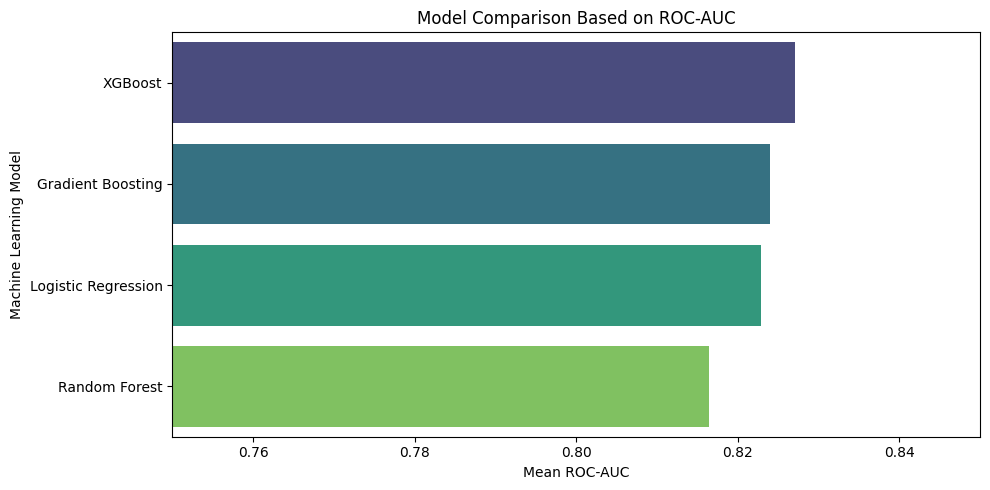

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Gradient Boosting',
        'XGBoost'
    ],
    'Mean ROC-AUC': [
        0.8229,
        0.8165,
        0.8240,
        0.8271
    ],
    'Standard Deviation': [
        0.0128,
        0.0137,
        0.0130,
        0.0130
    ]
})

results = results.sort_values(
    by='Mean ROC-AUC',
    ascending=False
)

display(results)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x='Mean ROC-AUC',
    y='Model',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title('Model Comparison Based on ROC-AUC')
plt.xlabel('Mean ROC-AUC')
plt.ylabel('Machine Learning Model')
plt.xlim(0.75, 0.85)
plt.tight_layout()
plt.show()

In [ ]:
flu_df = hospital_df[
    hospital_df["surveillance_network"].str.contains(
        "flu|influenza",
        case=False,
        na=False
    )
].copy()

print("Influenza dataset shape:", flu_df.shape)

display(flu_df.head(10))


Influenza dataset shape: (7598, 12)


,surveillance_network,season,date_type,date,age_category,race,sex,state,data_type,estimate_type,rate_type,estimate
33827,FluSurv-NET,2021-22,Week Ending Date,2021-12-04,Overall,All,All,Utah,Cumulative Rate,"Rate per 100,000",Observed,0.0
33828,FluSurv-NET,2021-22,Week Ending Date,2021-12-11,Overall,All,All,Utah,Cumulative Rate,"Rate per 100,000",Observed,1.0
33829,FluSurv-NET,2021-22,Week Ending Date,2021-12-18,Overall,All,All,Utah,Cumulative Rate,"Rate per 100,000",Observed,1.0
33830,FluSurv-NET,2021-22,Week Ending Date,2021-12-25,Overall,All,All,Utah,Cumulative Rate,"Rate per 100,000",Observed,2.0
33831,FluSurv-NET,2021-22,Week Ending Date,2022-01-01,Overall,All,All,Utah,Cumulative Rate,"Rate per 100,000",Observed,3.0
33832,FluSurv-NET,2021-22,Week Ending Date,2022-01-08,Overall,All,All,Utah,Cumulative Rate,"Rate per 100,000",Observed,5.0
33833,FluSurv-NET,2021-22,Week Ending Date,2022-01-15,Overall,All,All,Utah,Cumulative Rate,"Rate per 100,000",Observed,6.0
33834,FluSurv-NET,2021-22,Week Ending Date,2022-01-22,Overall,All,All,Utah,Cumulative Rate,"Rate per 100,000",Observed,7.0
33835,FluSurv-NET,2021-22,Week Ending Date,2022-01-29,Overall,All,All,Utah,Cumulative Rate,"Rate per 100,000",Observed,8.0
33836,FluSurv-NET,2021-22,Week Ending Date,2022-02-05,Overall,All,All,Utah,Cumulative Rate,"Rate per 100,000",Observed,9.0


In [ ]:

# Convert estimates into numeric values

flu_df["estimate"] = pd.to_numeric(
    flu_df["estimate"],
    errors="coerce"
)

print("Hospitalisation estimate summary:")
print(flu_df["estimate"].describe())

print("\nEstimates by age category:")
display(
    flu_df.groupby("age_category")["estimate"]
    .mean()
    .sort_values(ascending=False)
)

print("\nEstimates by season:")
display(
    flu_df.groupby("season")["estimate"]
    .mean()
)


Hospitalisation estimate summary:
count    7598.000000
mean       58.808107
std        85.057707
min         0.000000
25%         5.000000
50%        35.000000
75%        78.000000
max       845.000000
Name: estimate, dtype: float64

Estimates by age category:


,estimate
age_category,
85+ yr,294.536232
75-84 yr,195.856322
75+ yr,143.260870
65+ yr,137.895735
65-74 yr,84.498141
0-<1 yr,80.279070
50-64 yr,50.893204
Adults,46.995536
Overall,45.339460



Estimates by season:


,estimate
season,
2018-19,32.731618
2019-20,39.094395
2020-21,0.580645
2021-22,9.580855
2022-23,61.109108
2023-24,73.633904
2024-25,75.482830
2025-26,89.621402
2026-27,5.102273


In [ ]:

flu_df.to_csv(
    "USA_influenza_hospitalisation_data.csv",
    index=False
)

print("Influenza dataset saved successfully!")


Influenza dataset saved successfully!


In [ ]:

# Check the filtered dataset
print("Influenza records:", flu_df.shape[0])

# Check available columns
print("\nColumns:")
print(flu_df.columns.tolist())

# Convert estimate to numeric
flu_df["estimate"] = pd.to_numeric(
    flu_df["estimate"], errors="coerce"
)

# Overall estimate summary
print("\nHospitalisation estimate summary:")
display(flu_df["estimate"].describe())

# Average estimate by age group
print("\nHospitalisation estimates by age:")
age_analysis = (
    flu_df.groupby("age_category")["estimate"]
    .mean()
    .sort_values(ascending=False)
)
display(age_analysis)

# Average estimate by season
print("\nHospitalisation estimates by season:")
season_analysis = flu_df.groupby("season")["estimate"].mean()
display(season_analysis)


Influenza records: 7598

Columns:
['surveillance_network', 'season', 'date_type', 'date', 'age_category', 'race', 'sex', 'state', 'data_type', 'estimate_type', 'rate_type', 'estimate']

Hospitalisation estimate summary:


,estimate
count,7598.000000
mean,58.808107
std,85.057707
min,0.000000
25%,5.000000
50%,35.000000
75%,78.000000
max,845.000000



Hospitalisation estimates by age:


,estimate
age_category,
85+ yr,294.536232
75-84 yr,195.856322
75+ yr,143.260870
65+ yr,137.895735
65-74 yr,84.498141
0-<1 yr,80.279070
50-64 yr,50.893204
Adults,46.995536
Overall,45.339460



Hospitalisation estimates by season:


,estimate
season,
2018-19,32.731618
2019-20,39.094395
2020-21,0.580645
2021-22,9.580855
2022-23,61.109108
2023-24,73.633904
2024-25,75.482830
2025-26,89.621402
2026-27,5.102273


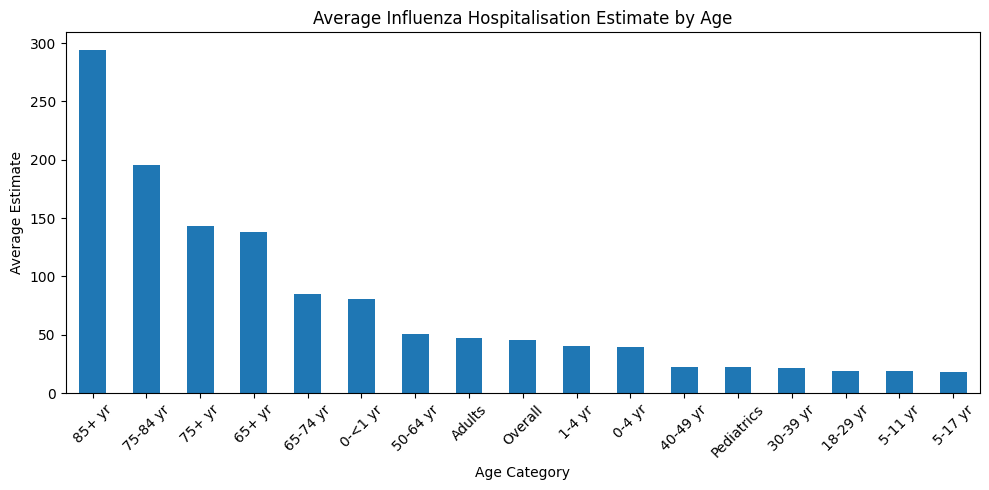

In [ ]:

import matplotlib.pyplot as plt

age_analysis.plot(kind="bar", figsize=(10, 5))

plt.title("Average Influenza Hospitalisation Estimate by Age")
plt.xlabel("Age Category")
plt.ylabel("Average Estimate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

# Check the types of estimates
print("Data types:")
print(flu_df["data_type"].value_counts())

print("\nEstimate types:")
print(flu_df["estimate_type"].value_counts())

print("\nRate types:")
print(flu_df["rate_type"].value_counts())

# Show average estimates by age and estimate type
age_comparison = (
    flu_df.groupby(
        ["age_category", "data_type", "estimate_type", "rate_type"],
        dropna=False
    )["estimate"]
    .mean()
    .reset_index()
)

display(age_comparison.sort_values("estimate", ascending=False))


Data types:
data_type
Cumulative Rate    7598
Name: count, dtype: int64

Estimate types:
estimate_type
Rate per 100,000    7598
Name: count, dtype: int64

Rate types:
rate_type
Observed    7598
Name: count, dtype: int64


,age_category,data_type,estimate_type,rate_type,estimate
13,85+ yr,Cumulative Rate,"Rate per 100,000",Observed,294.536232
12,75-84 yr,Cumulative Rate,"Rate per 100,000",Observed,195.856322
11,75+ yr,Cumulative Rate,"Rate per 100,000",Observed,143.260870
9,65+ yr,Cumulative Rate,"Rate per 100,000",Observed,137.895735
10,65-74 yr,Cumulative Rate,"Rate per 100,000",Observed,84.498141
1,0-<1 yr,Cumulative Rate,"Rate per 100,000",Observed,80.279070
8,50-64 yr,Cumulative Rate,"Rate per 100,000",Observed,50.893204
14,Adults,Cumulative Rate,"Rate per 100,000",Observed,46.995536
15,Overall,Cumulative Rate,"Rate per 100,000",Observed,45.339460
2,1-4 yr,Cumulative Rate,"Rate per 100,000",Observed,40.187500


In [ ]:

# Compare hospitalisation rates by age and season

age_season = (
    flu_df.groupby(
        ["season", "age_category"]
    )["estimate"]
    .mean()
    .reset_index()
)

print("Hospitalisation rates by age and season:")
display(age_season)

# Overall average by age group
age_summary = (
    flu_df.groupby("age_category")["estimate"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

print("\nAverage hospitalisation rate by age:")
display(age_summary)

print("\nHighest hospitalisation rate:")
display(age_summary.head(1))

print("\nLowest hospitalisation rate:")
display(age_summary.tail(1))


Hospitalisation rates by age and season:


,season,age_category,estimate
0,2018-19,0-4 yr,31.064516
1,2018-19,1-4 yr,47.692308
2,2018-19,40-49 yr,24.437500
3,2018-19,5-11 yr,11.225806
4,2018-19,5-17 yr,8.193548
...,...,...,...
109,2026-27,65+ yr,12.000000
110,2026-27,65-74 yr,8.750000
111,2026-27,75-84 yr,14.000000
112,2026-27,85+ yr,23.750000



Average hospitalisation rate by age:


,age_category,estimate
0,85+ yr,294.536232
1,75-84 yr,195.856322
2,75+ yr,143.260870
3,65+ yr,137.895735
4,65-74 yr,84.498141
5,0-<1 yr,80.279070
6,50-64 yr,50.893204
7,Adults,46.995536
8,Overall,45.339460
9,1-4 yr,40.187500



Highest hospitalisation rate:


,age_category,estimate
0,85+ yr,294.536232



Lowest hospitalisation rate:


,age_category,estimate
16,5-17 yr,17.884758


In [ ]:

age_summary["rate_percentage"] = (
    age_summary["estimate"] / 100000
) * 100

display(age_summary)


,age_category,estimate,rate_percentage
0,85+ yr,294.536232,0.294536
1,75-84 yr,195.856322,0.195856
2,75+ yr,143.260870,0.143261
3,65+ yr,137.895735,0.137896
4,65-74 yr,84.498141,0.084498
5,0-<1 yr,80.279070,0.080279
6,50-64 yr,50.893204,0.050893
7,Adults,46.995536,0.046996
8,Overall,45.339460,0.045339
9,1-4 yr,40.187500,0.040188


In [56]:

# Calculate estimated hospitalisations per 100,000 people
age_summary["estimated_hospitalisations"] = (
    age_summary["estimate"]
)

# Calculate estimated cost per 100,000 people
age_summary["hospitalisation_cost"] = (
    age_summary["estimated_hospitalisations"] * 25000
)

print("Hospitalisation cost by age group:")
display(
    age_summary.sort_values(
        "hospitalisation_cost",
        ascending=False
    )
)


Hospitalisation cost by age group:


,age_category,estimate,rate_percentage,estimated_hospitalisations,hospitalisation_cost
0,85+ yr,294.536232,0.294536,294.536232,7.363406e+06
1,75-84 yr,195.856322,0.195856,195.856322,4.896408e+06
2,75+ yr,143.260870,0.143261,143.260870,3.581522e+06
3,65+ yr,137.895735,0.137896,137.895735,3.447393e+06
4,65-74 yr,84.498141,0.084498,84.498141,2.112454e+06
5,0-<1 yr,80.279070,0.080279,80.279070,2.006977e+06
6,50-64 yr,50.893204,0.050893,50.893204,1.272330e+06
7,Adults,46.995536,0.046996,46.995536,1.174888e+06
8,Overall,45.339460,0.045339,45.339460,1.133487e+06
9,1-4 yr,40.187500,0.040188,40.187500,1.004688e+06


In [57]:

# Check all available CDC data dimensions

print("Available columns:")
print(flu_df.columns.tolist())

print("\nSurveillance networks:")
print(flu_df["surveillance_network"].value_counts())

print("\nAvailable seasons:")
print(flu_df["season"].value_counts())

print("\nAge categories:")
print(flu_df["age_category"].unique())

print("\nEstimate types:")
print(flu_df["estimate_type"].value_counts())


Available columns:
['surveillance_network', 'season', 'date_type', 'date', 'age_category', 'race', 'sex', 'state', 'data_type', 'estimate_type', 'rate_type', 'estimate']

Surveillance networks:
surveillance_network
FluSurv-NET    7598
Name: count, dtype: int64

Available seasons:
season
2023-24    1811
2025-26    1355
2021-22    1076
2022-23    1054
2024-25     961
2019-20     678
2018-19     544
2026-27      88
2020-21      31
Name: count, dtype: int64

Age categories:
['Overall' 'Adults' '75+ yr' '85+ yr' '1-4 yr' '5-11 yr' '30-39 yr'
 'Pediatrics' '75-84 yr' '0-4 yr' '18-29 yr' '5-17 yr' '65-74 yr' '65+ yr'
 '0-<1 yr' '40-49 yr' '50-64 yr']

Estimate types:
estimate_type
Rate per 100,000    7598
Name: count, dtype: int64
